# Residual analysis

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Evaluating regression models with RMSE, MAE, R², bias and residual maps
</div>
<!-- markdownlint-enable MD033 -->

---

You have a trained model and predictions for 2018 and 2026. This page evaluates how good these predictions are, with aggregate metrics, a scatter plot and {term}`residual <Residual>` maps, and separately for the area the model was trained on, the held-out area and the new year, because a single number for the whole scene would hide exactly the differences that matter.

---

## 1. Motivation

A single RMSE value can look perfectly reasonable while hiding a specific region or surface type where the model performs poorly, exactly the kind of blind spot that matters if your project depends on accuracy there. Reading metrics, plots and maps together, and computing metrics for meaningful subsets, is what catches this.

---

## 2. Core idea

Regression evaluation combines a small set of numbers with two kinds of plots:

| Tool | Question it answers |
| --- | --- |
| {term}`RMSE <Root Mean Squared Error>` | How large is a typical error, with large errors weighted more? (target units) |
| {term}`MAE <Mean Absolute Error>` | How large is the average error? (target units) |
| Bias (mean error) | Are predictions systematically too high or too low? (target units) |
| {term}`R² <R-squared>` | Which share of the variation in the target does the model explain? (0–1) |
| {term}`Pearson correlation <Pearson Correlation>` *r* | Do predictions rise and fall with the target, even if shifted? (−1 to 1) |
| Scatter plot | Does the error depend on the value (e.g. high values underestimated)? |
| Residual map | Where are the errors, and do they cluster? |

Here the **residual** is prediction minus reference: positive means the model predicted too high.

---

## 3. Workflow

### A. Load predictions and reference maps

In [1]:
import json
import logging
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
logging.getLogger("rasterio").setLevel(logging.ERROR)

import geoai
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

latest_file = Path("regression_runs/latest.json")
if not latest_file.exists():
    raise FileNotFoundError("Run pages 5 and 6 first: they train the model and create the predictions.")
latest = json.loads(latest_file.read_text())
PRED_DIR = Path("regression_runs") / latest["experiment"] / "predictions"
if not (PRED_DIR / "ndvi_2026.tif").exists():
    raise FileNotFoundError("Run the previous page first: it creates the predictions.")
print("Experiment:", latest["experiment"])

def read(path):
    with rasterio.open(path) as src:
        arr = src.read(1).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
    return arr

pred = {y: read(PRED_DIR / f"ndvi_{y}.tif") for y in [2018, 2026]}
ref = {y: read(f"data/beni_s2_{y}_ndvi.tif") for y in [2018, 2026]}

SPLIT_ROW = json.loads(Path("regression_tiles/beni_2018/split.json").read_text())["split_row"]
rows = np.arange(ref[2018].shape[0])[:, None] * np.ones(ref[2018].shape[1], bool)
area = {"north (training area)": rows < SPLIT_ROW, "south (held out)": rows >= SPLIT_ROW}

Experiment: unet-resnet34_all_mse_lr0.001_seed0


`area` holds two masks: the northern part of the scene, where the training tiles came from, and the southern part held out on page 4.

### B. The three-panel comparison

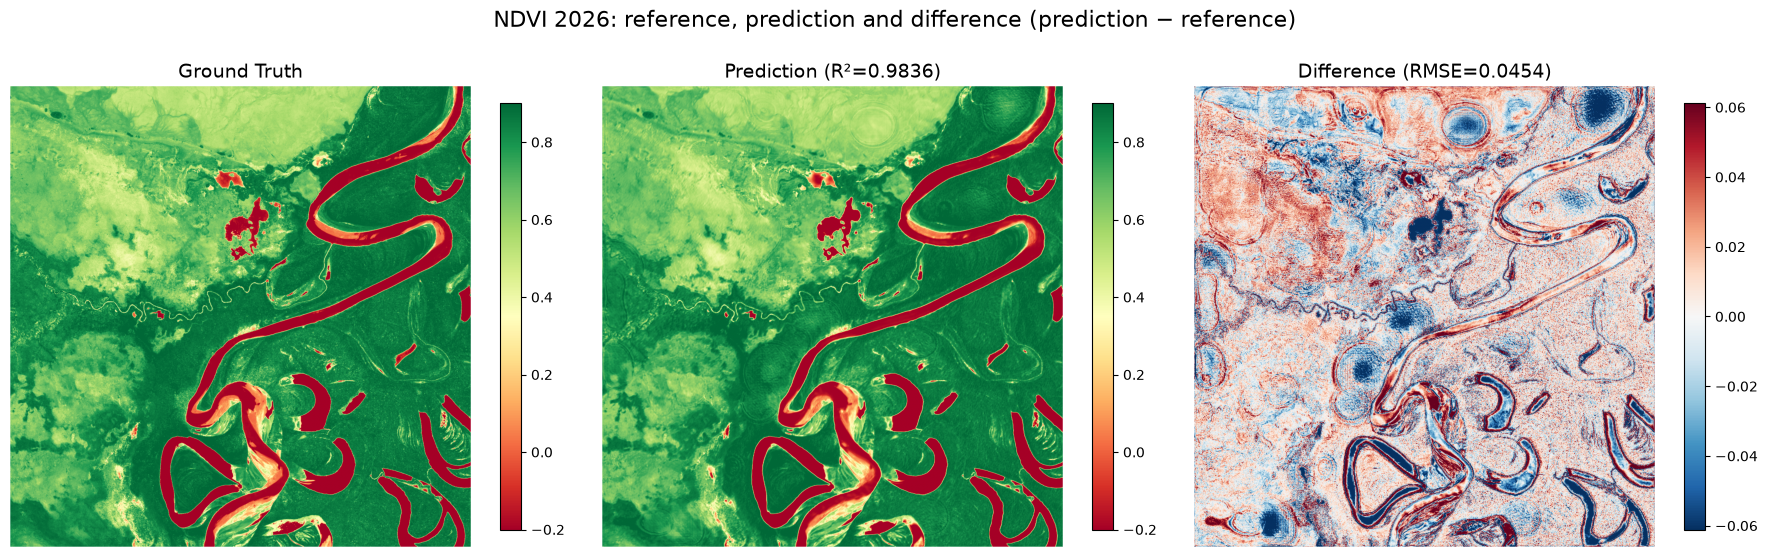

In [2]:
fig, metrics_2026 = geoai.plot_regression_comparison(
    true_raster="data/beni_s2_2026_ndvi.tif",
    pred_raster=str(PRED_DIR / "ndvi_2026.tif"),
    title="NDVI 2026: reference, prediction and difference (prediction − reference)",
    cmap="RdYlGn",
    vmin=-0.2,
    vmax=0.9,
    valid_range=(-1.0, 1.0),
)

The function shows reference, prediction and their difference side by side, and returns the metrics for the whole scene. The colour scale of the difference panel is set automatically to the 5th and 95th percentiles of the differences, so even a very good model shows strong colours there; read the colour bar. Most of the scene is pale, and the strongest differences trace the river banks, sand bars and lake shores.

`valid_range=(-1, 1)` excludes pixels outside the valid NDVI range from the metrics. With `clip_range` applied during prediction there are none here, but for unclipped predictions or noisy reference data this keeps a few impossible values from distorting the result.

### C. Metrics by area and year

In [3]:
def regression_metrics(reference, prediction, mask=None):
    """RMSE, MAE, bias, R² and Pearson r for the valid pixels inside mask."""
    valid = np.isfinite(reference) & np.isfinite(prediction)
    if mask is not None:
        valid &= mask
    t, p = reference[valid], prediction[valid]
    e = p - t
    return {
        "pixels": valid.sum(),
        "RMSE": np.sqrt(np.mean(e**2)),
        "MAE": np.mean(np.abs(e)),
        "bias": np.mean(e),
        "R²": 1 - np.sum(e**2) / np.sum((t - t.mean()) ** 2),
        "r": np.corrcoef(t, p)[0, 1],
    }

table = pd.DataFrame(
    [{"year": y, "area": name, **regression_metrics(ref[y], pred[y], mask)}
     for y in [2018, 2026] for name, mask in area.items()]
)
table.round(4)

,year,area,pixels,RMSE,MAE,bias,R²,r
0,2018,north (training area),1532454,0.0422,0.0259,0.0021,0.9798,0.9900
1,2018,south (held out),711550,0.0435,0.0249,0.0051,0.9908,0.9955
2,2026,north (training area),1532454,0.0378,0.0245,0.0012,0.9826,0.9913
3,2026,south (held out),711550,0.0587,0.0328,-0.0023,0.9841,0.9921


Four numbers per row, four rows. In 2018, the model is about as accurate in the held-out south (RMSE 0.044) as in the north it was trained on (0.042): the spatial split shows that it transfers to a new area of the same scene. In 2026 the error in the south rises to 0.059, the largest of the four: new year *and* new area, and the south, a third of the scene, contains more than half of the pixels whose NDVI changed by more than 0.3. Bias is close to zero everywhere (less than 0.01), so the errors are random rather than systematic. R² is highest in the south because the south contains more water and therefore more variation for the model to explain, a reminder that R² depends on the data as much as on the model.

```{admonition} Which of these numbers would you report?
:class: important
The northern 2018 numbers describe how well the model fits data it was trained on; they are not an accuracy estimate. The southern 2018 numbers estimate accuracy in a new area, and the 2026 numbers in a new year. For a project report, give the held-out numbers, and say what was held out.
```

### D. Scatter plot

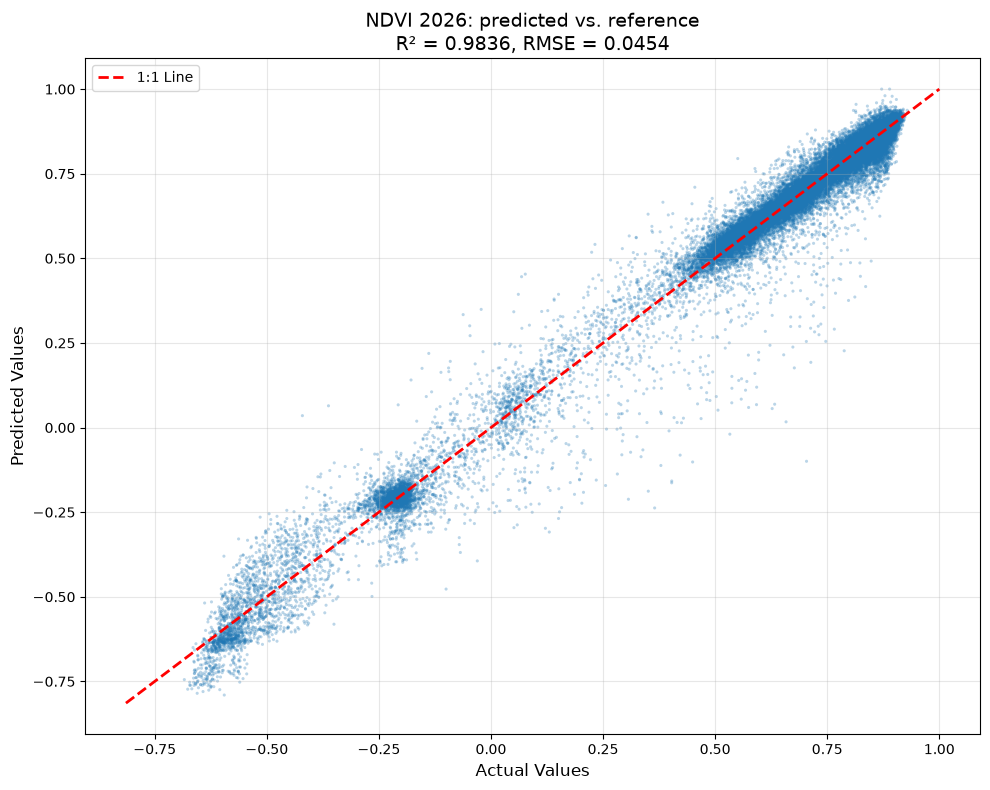

Fitted line with float32 values: prediction = 0.500 × reference + 0.364
Fitted line with float64 values: prediction = 0.996 × reference + 0.003


In [4]:
fig, scatter_metrics = geoai.plot_scatter(
    true_raster="data/beni_s2_2026_ndvi.tif",
    pred_raster=str(PRED_DIR / "ndvi_2026.tif"),
    sample_size=50000,
    valid_range=(-1.0, 1.0),
    fit_line=False,
    title="NDVI 2026: predicted vs. reference",
)

valid = np.isfinite(ref[2026]) & np.isfinite(pred[2026])
slope32, intercept32 = np.polyfit(ref[2026][valid], pred[2026][valid], 1)  # float32, as geoai does
slope, intercept = np.polyfit(ref[2026][valid].astype("float64"), pred[2026][valid].astype("float64"), 1)
print(f"Fitted line with float32 values: prediction = {slope32:.3f} × reference + {intercept32:.3f}")
print(f"Fitted line with float64 values: prediction = {slope:.3f} × reference + {intercept:.3f}")

In a perfect model all points lie on the red 1:1 line. A line fitted through the points tells you whether the model compresses the range: a slope below 1 means high values are predicted too low and low values too high, the typical "regression to the mean" of a model that is unsure. Here the fitted slope is close to 1 and the intercept close to 0: no measurable compression. The spread is largest at intermediate values (0 to 0.5), the mixed pixels of sand bars and river banks.

```{admonition} Why we fit the line ourselves
:class: warning
`plot_scatter()` can also draw the fitted line (`fit_line=True`). In `geoai` 0.43 it fits the line on the `float32` values of the rasters, and with more than two million pixels that calculation becomes numerically unstable. The first line of the output above repeats that calculation: its slope and intercept contradict the plot, in which the points follow the 1:1 line. Converting the values to `float64` first (second line) gives the correct fit. When a number contradicts what a plot shows, trust neither until you have checked the calculation.
```

### E. Errors by surface type

An overall RMSE mixes surfaces that are easy and difficult to predict. Grouping the residuals by the reference NDVI, and by whether a pixel changed between 2018 and 2026, shows where the errors come from:

,share,RMSE,MAE,bias
group,,,,
water (NDVI < 0),0.0961,0.0719,0.0523,0.0014
"sand, bare, mixed (0–0.4)",0.0266,0.1201,0.0841,-0.0040
"savanna, grassland (0.4–0.75)",0.3582,0.0454,0.0272,0.0036
forest (≥ 0.75),0.5191,0.0294,0.0196,-0.0024
changed since 2018 (|ΔNDVI| > 0.3),0.0834,0.0862,0.0565,-0.0018
all pixels,1.0000,0.0454,0.0272,0.0000


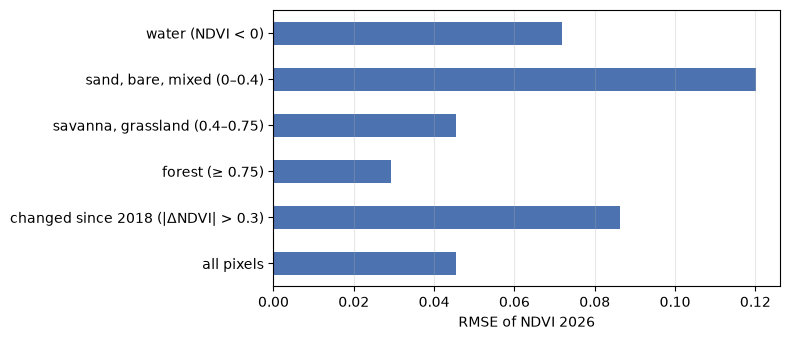

In [5]:
groups = {
    "water (NDVI < 0)": ref[2026] < 0,
    "sand, bare, mixed (0–0.4)": (ref[2026] >= 0) & (ref[2026] < 0.4),
    "savanna, grassland (0.4–0.75)": (ref[2026] >= 0.4) & (ref[2026] < 0.75),
    "forest (≥ 0.75)": ref[2026] >= 0.75,
    "changed since 2018 (|ΔNDVI| > 0.3)": np.abs(ref[2026] - ref[2018]) > 0.3,
    "all pixels": np.ones(ref[2026].shape, bool),
}
by_group = pd.DataFrame(
    [{"group": name, **regression_metrics(ref[2026], pred[2026], mask)} for name, mask in groups.items()]
).set_index("group")
by_group["share"] = by_group["pixels"] / by_group.loc["all pixels", "pixels"]
display(by_group[["share", "RMSE", "MAE", "bias"]].round(4))

fig, ax = plt.subplots(figsize=(8, 3.5))
by_group["RMSE"].plot.barh(ax=ax, color="#4c72b0")
ax.invert_yaxis()
ax.set_xlabel("RMSE of NDVI 2026")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Forest, half of the scene, is predicted best (RMSE 0.03). Errors are more than twice as large for water and four times as large for sand, bare ground and mixed pixels (0.12), although these make up only 3% of the scene. Pixels that changed since 2018 have about twice the overall error. A scene-wide RMSE of 0.045 is dominated by the easy forest pixels and says little about the difficult surfaces.

R² is deliberately left out of this table: within a group, the reference values vary much less than across the whole scene, so R² can be low even when the errors are small. RMSE, MAE and bias stay comparable across groups because they are in NDVI units.

### F. R² and correlation are not the same

A quick experiment shows why both are reported. We add a constant offset of +0.05 to the 2026 prediction, as a miscalibrated sensor or a systematic model error would:

In [6]:
shifted = pred[2026] + 0.05
pd.DataFrame(
    [regression_metrics(ref[2026], pred[2026]), regression_metrics(ref[2026], shifted)],
    index=["prediction", "prediction + 0.05"],
).round(4)

,pixels,RMSE,MAE,bias,R²,r
prediction,2244004,0.0454,0.0272,0.00,0.9836,0.9918
prediction + 0.05,2244004,0.0676,0.0573,0.05,0.9637,0.9918


The correlation *r* does not change at all: the shifted predictions still rise and fall exactly with the reference. RMSE, bias and R² do change, because they measure agreement, not just co-variation. A high *r* with a low R² is the signature of a systematic offset or scaling problem, which you could correct, unlike random scatter.

### G. Reading the residual map

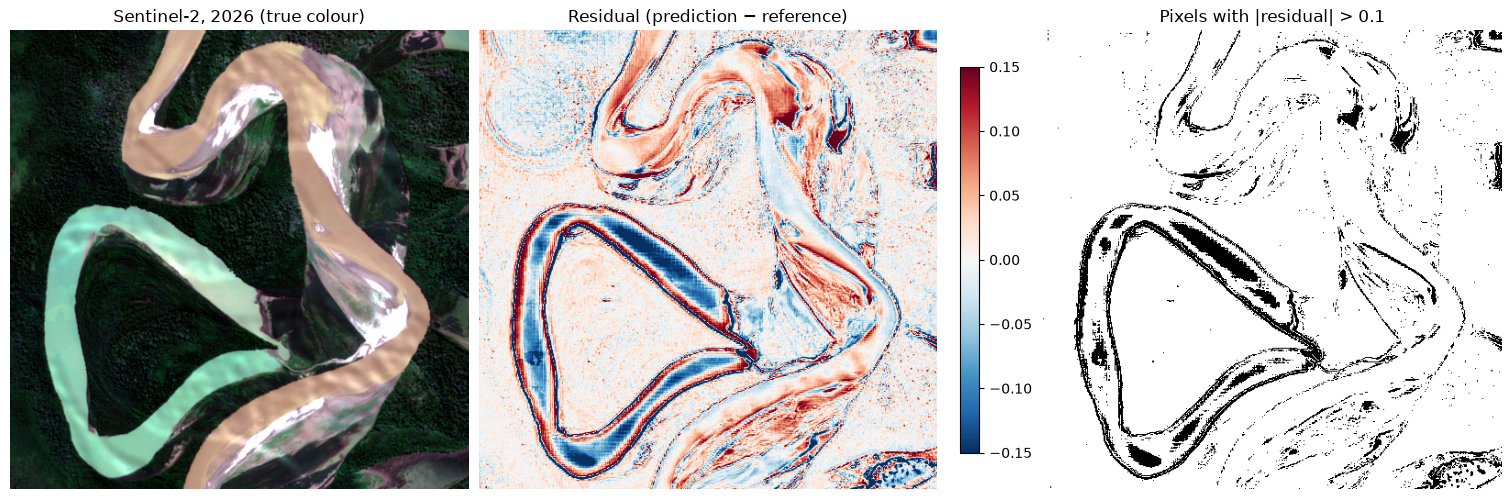

Share of pixels with |residual| > 0.1: 3.7%


In [7]:
residual = pred[2026] - ref[2026]
zoom = (slice(950, 1450), slice(450, 950))

fig, axes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
with rasterio.open("data/beni_s2_2026.tif") as src:
    rgb = src.read([3, 2, 1]).astype("float32")[(slice(None),) + zoom]
lo, hi = np.percentile(rgb, (2, 98), axis=(1, 2), keepdims=True)
axes[0].imshow(np.clip((rgb - lo) / (hi - lo), 0, 1).transpose(1, 2, 0))
axes[0].set_title("Sentinel-2, 2026 (true colour)")
im = axes[1].imshow(residual[zoom], cmap="RdBu_r", vmin=-0.15, vmax=0.15)
axes[1].set_title("Residual (prediction − reference)")
fig.colorbar(im, ax=axes[1], shrink=0.8)
im = axes[2].imshow(np.abs(residual[zoom]) > 0.1, cmap="Greys")
axes[2].set_title("Pixels with |residual| > 0.1")
for ax in axes:
    ax.set_axis_off()
plt.show()
print(f"Share of pixels with |residual| > 0.1: {np.nanmean(np.abs(residual) > 0.1):.1%}")

Errors larger than 0.1 affect only about 4% of the scene, and they are not random: they trace every land–water boundary, where a 10 m pixel mixes water and vegetation, and fill the new oxbow lake, whose shallow, turquoise water hardly occurs in the northern training area and is predicted too low throughout. On the whole-scene map in step B you can also see faint round patches, about 1 km across, with errors of about −0.05. They have no counterpart in any input band and appear at partly the same places in both years: an artefact of the network itself. They are small, but they are exactly the kind of structure that only a residual map reveals.

```{admonition} A residual map answers a question metrics cannot
:class: important
"What is my average error?" and "where is my model wrong?" are different questions. Here the answer to the second one is: along every land–water boundary. If your project were about river banks, erosion or sand bars, the scene-wide RMSE would badly overstate the quality of the map for your purpose.
```

---

## 4. Python reactivation

`regression_metrics()` is a small function that returns a dictionary. Calling it inside a list comprehension and passing the list to `pd.DataFrame()` builds a complete results table in one step, a pattern worth reusing whenever you compute the same statistics for several subsets:

```python
pd.DataFrame([{"name": name, **regression_metrics(t, p, mask)} for name, mask in masks.items()])
```

`**` unpacks the returned dictionary into the row, so every metric becomes a column. Boolean masks such as `ref[2026] < 0` select subsets of pixels without loops.

---

## 5. Common pitfalls

- **Reporting scores from the training area as accuracy.** They describe the fit, not how well the model works elsewhere; report held-out scores.
- **Trusting a single aggregate metric without checking the residual map.** A good scene-wide RMSE can coexist with poor performance exactly where your project needs it.
- **Confusing R² with correlation.** A systematic offset leaves *r* unchanged but lowers R²; report both, plus the bias.
- **Comparing R² between subsets with different variability.** Within a narrow range of values, R² drops even when errors are small; compare RMSE or MAE instead.
- **Including nodata values in your own statistics.** Convert them to `np.nan` first, as `read()` does.

---

## 6. Mini task

1. Re-run this page after training with `BANDS = "rgb"` on page 5 (and predicting on page 6). Which surface type in step E suffers most from the missing NIR band?
2. Your model reports RMSE 0.06 and R² 0.82 for a held-out area. The residual map shows small, scattered errors almost everywhere, except a coherent strip of large positive residuals along a reservoir shoreline. What would you investigate first, and why?

:::{dropdown} Sample solution
:class: note

1. In our RGB run, all groups got worse, but very unequally. Forest errors rose by about 30% (RMSE 0.029 to 0.039) and savanna by about 60%, while water errors more than tripled (0.07 to 0.25) and those of sand, bare and mixed pixels and of changed areas roughly doubled to 0.22–0.23. Without NIR, the model can no longer tell reliably how much vegetation a dark or bright surface contains. The scene-wide RMSE for 2026 rose from 0.045 to 0.099.

2. The shoreline strip first: it is spatially coherent (not noise), and it is a systematic failure that the scene-wide RMSE and R² hide. Likely causes are mixed water–vegetation pixels, a different water level between the imagery and the reference data, or a surface type that is rare in the training data. Check the imagery and the reference at a few of these locations, and compute the metrics for a shoreline buffer separately, before deciding whether the model is good enough for an application near the shore.
:::

---

## 7. Key takeaways

- RMSE, MAE and bias are in target units and answer "how large are the errors"; R² and *r* are unitless and answer "how well is the variation reproduced".
- Evaluate separately for the training area, a held-out area and a new date; only the held-out numbers estimate accuracy.
- Scatter plots reveal value-dependent errors, such as a compressed range (slope below 1).
- Grouping residuals by surface type and mapping them shows where a model fails; for this model, at land–water boundaries.
- A systematic offset leaves the correlation unchanged but lowers R², so report both, plus the bias.

### Further reading

- Willmott and Matsuura (2005), ["Advantages of the mean absolute error (MAE) over the root mean square error (RMSE) in assessing average model performance"](https://doi.org/10.3354/cr030079), *Climate Research* 30, 79–82 — why MAE is often the easier error measure to interpret.
- Ploton et al. (2020), ["Spatial validation reveals poor predictive performance of large-scale ecological mapping models"](https://doi.org/10.1038/s41467-020-18321-y), *Nature Communications* 11, 4540 — how random validation overstated the accuracy of a biomass map, and what spatial validation showed instead.